# 09 — Shor, en simulador (y por qué solo en simulador)

**Curso ECCI 2026 · Computación cuántica**

Este notebook tiene una particularidad: **no tiene celda de envío a
hardware**,
y esa ausencia es parte del contenido.

Shor es el algoritmo que puso a la computación cuántica en los diarios,
porque
rompe RSA. También es el que peor se comporta en NISQ: lo que se publica
como
"Shor en hardware" son, casi siempre, circuitos precompilados sabiendo la
respuesta. Acá lo corremos completo en simulador, donde funciona de verdad,
y
después medimos exactamente por qué no sobrevive al ruido.

Recorrido:

1. De factorizar a encontrar períodos: la reducción clásica.
2. La función $a^x \bmod N$ y su periodicidad.
3. **El problema del autoestado, resuelto**: por qué $|1\rangle$ alcanza.
4. El circuito para $N = 15$, $a = 7$, con la cuenta etapa por etapa.
5. Los picos, las fracciones continuas, y los factores.
6. El algoritmo completo, corrido muchas veces.
7. **Por qué en NISQ sale ruido plano**, con los números.

Depende de `07` (QFT) y `08` (QPE): Shor es QPE aplicado a un operador
aritmético.

## Preámbulo: entorno

Esta celda no hace nada en el entorno local (el env `quantum`, que ya tiene
todo instalado). Solo actúa si el notebook corre en **Google Colab**, donde
instala lo que falta.

`plotly` e `ipywidgets` vienen con Colab, así que no se instalan.

**Sobre `utils.py`:** los notebooks importan ese módulo, que en el entorno
local está en la misma carpeta. En Colab la celda lo **baja solo** de un
archivo de Drive compartido como "cualquiera con el link puede ver", así que
funciona para cualquiera que abra el notebook sin que tenga que autenticarse.

Dos detalles de esa descarga:

- se usa el endpoint `drive.usercontent.google.com`, porque la URL clásica
  `uc?export=download` devuelve la página de aviso de antivirus en vez del
  archivo;
- solo baja si `utils` no está ya disponible, de modo que una **subida manual
  al panel de archivos tiene prioridad** sobre la copia de Drive.

Si el archivo de Drive se actualiza con *Administrar versiones*, el ID y el
link se mantienen, y los notebooks siguen apuntando al lugar correcto.

In [1]:
import importlib.util
import sys

try:                      # find_spec("google.colab") falla si no existe el padre
    import google.colab   # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !pip install qiskit
    !pip install qiskit-ibm-runtime
    !pip install qiskit_aer
    !pip install pylatexenc

    # utils.py desde Drive, compartido como "cualquiera con el link puede ver".
    # Se usa el endpoint drive.usercontent, que entrega el archivo directo; la
    # URL clásica uc?export=download devuelve la página de aviso de antivirus.
    # Solo se baja si no está ya presente, así una subida manual tiene prioridad.
    UTILS_ID = "1_VyKXtDMVqnJHcGepeARhoEY4tikLSDg"
    if importlib.util.find_spec("utils") is None:
        !wget -q -O utils.py "https://drive.usercontent.google.com/download?id=$UTILS_ID&export=download&confirm=t"
        importlib.invalidate_caches()
        if importlib.util.find_spec("utils") is None:
            print("No se pudo bajar utils.py: subirlo a mano desde el panel de archivos.")
        else:
            print("utils.py descargado de Drive")
else:
    print("entorno local: no hay nada que instalar")

try:
    import utils
    print(f"utils.py versión {utils.__version__}")
except ImportError:
    print("utils.py todavía no está disponible")

entorno local: no hay nada que instalar


utils.py versión 2026-09-19


In [2]:
import math
from fractions import Fraction

import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit
from qiskit.quantum_info import Operator, Statevector
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeFez

import plotly.io as pio

import utils

utils.estilo()
pio.renderers.default = "plotly_mimetype"
fez = FakeFez()
MARCAS = "①②③④⑤⑥⑦⑧⑨"


def marca(qc, n):
    qc.barrier(label=MARCAS[n - 1])
    return qc


N, A = 15, 7
print(f"vamos a factorizar N = {N} usando a = {A}")

vamos a factorizar N = 15 usando a = 7


## Autenticación (opcional, y en memoria)

Este notebook no manda nada a hardware. La celda está por consistencia, y
por
si hace falta mirar propiedades del backend para la sección 7.

In [3]:
from getpass import getpass

from qiskit_ibm_runtime import QiskitRuntimeService

CRN = "crn:v1:bluemix:public:quantum-computing:us-east:a/1a958fc8c19b451ba71d1d0d94d52a44:9153727a-cc43-46be-a974-dfe1f29b4bcb::"

AUTENTICAR = False

service = None
if AUTENTICAR:
    service = QiskitRuntimeService(channel="ibm_cloud",
                                   token=getpass("API key: "),
                                   instance=CRN)
    print([b.name for b in service.backends()])
else:
    print("sin autenticar — este notebook corre entero en simulador, a propósito")

sin autenticar — este notebook corre entero en simulador, a propósito


---
# 1. De factorizar a encontrar períodos

**La parte cuántica de Shor no factoriza nada.** Encuentra el período de una
función. Toda la conexión con la factorización es clásica, y es del siglo
XVII.

Para factorizar $N$:

1. Elegir $a$ al azar, $1 < a < N$. Si $\gcd(a, N) \neq 1$, ya ganaste: ese
   gcd es un factor. (Con $N$ grande esto casi nunca pasa.)
2. Encontrá el **orden** de $a$ módulo $N$: el menor $r > 0$ con
   $$a^r \equiv 1 \pmod N .$$
3. Si $r$ es **impar**, volvé al paso 1.
4. Si $a^{r/2} \equiv -1 \pmod N$, volvé al paso 1.
5. Si no, entonces $\gcd(a^{r/2} \pm 1,\, N)$ son factores no triviales.

### Por qué funciona el paso 5

Si $a^r \equiv 1$, entonces $N$ divide a $a^r - 1 = (a^{r/2}-1)(a^{r/2}+1)$.
Así que los factores de $N$ están repartidos entre esos dos números. Si $N$
no
divide a ninguno por separado —que es lo que excluyen los pasos 3 y 4—
entonces cada uno se lleva parte, y el gcd los encuentra.

**El único paso difícil es el 2.** Clásicamente, encontrar el orden es tan
duro
como factorizar. Cuánticamente, es un problema de períodos, y ahí QPE lo
resuelve.

Los pasos 3 y 4 fallan con probabilidad $\le 1/2$, así que un par de
intentos
alcanzan.

In [4]:
def pasos_clasicos(N, a, r):
    """Los pasos 3 a 5, dado el período r que devolvería la parte cuántica."""
    if r % 2:
        return None, f"r = {r} es impar → elegir otro a"
    x = pow(a, r // 2, N)
    if x == N - 1:
        return None, f"a^(r/2) = {x} ≡ -1 (mod {N}) → elegir otro a"
    f1, f2 = math.gcd(x - 1, N), math.gcd(x + 1, N)
    if f1 in (1, N) and f2 in (1, N):
        return None, "los gcd salieron triviales → elegir otro a"
    return (f1, f2), f"a^(r/2) = {x};  gcd({x}-1, {N}) = {f1};  gcd({x}+1, {N}) = {f2}"


print(f"Órdenes módulo {N}, calculados a la fuerza bruta:\n")
print(f"{'a':>3} {'a^x mod N':<26} {'r':>3}  ¿sirve?")
for a in range(2, N):
    if math.gcd(a, N) != 1:
        print(f"{a:>3} {'gcd(a,N) = ' + str(math.gcd(a, N)):<26} {'-':>3}  "
              f"¡factor directo!")
        continue
    seq = [pow(a, k, N) for k in range(1, 9)]
    r = seq.index(1) + 1
    factores, motivo = pasos_clasicos(N, a, r)
    print(f"{a:>3} {str(seq[:5]) + '...':<26} {r:>3}  "
          f"{'sí → ' + str(factores) if factores else 'no: ' + motivo.split('→')[0].strip()}")

Órdenes módulo 15, calculados a la fuerza bruta:

  a a^x mod N                    r  ¿sirve?
  2 [2, 4, 8, 1, 2]...           4  sí → (3, 5)
  3 gcd(a,N) = 3                 -  ¡factor directo!
  4 [4, 1, 4, 1, 4]...           2  sí → (3, 5)
  5 gcd(a,N) = 5                 -  ¡factor directo!
  6 gcd(a,N) = 3                 -  ¡factor directo!
  7 [7, 4, 13, 1, 7]...          4  sí → (3, 5)
  8 [8, 4, 2, 1, 8]...           4  sí → (3, 5)
  9 gcd(a,N) = 3                 -  ¡factor directo!
 10 gcd(a,N) = 5                 -  ¡factor directo!
 11 [11, 1, 11, 1, 11]...        2  sí → (5, 3)
 12 gcd(a,N) = 3                 -  ¡factor directo!
 13 [13, 4, 7, 1, 13]...         4  sí → (3, 5)
 14 [14, 1, 14, 1, 14]...        2  no: a^(r/2) = 14 ≡ -1 (mod 15)


---
# 2. La función, y su período

Para $a = 7$, $N = 15$:

$$7^0 = 1,\; 7^1 = 7,\; 7^2 = 4,\; 7^3 = 13,\; 7^4 = 1,\; 7^5 = 7,\ldots$$

**Período $r = 4$.** Y como $r$ es par y $7^2 = 4 \neq 14 \equiv -1$, los
pasos
clásicos van a funcionar.

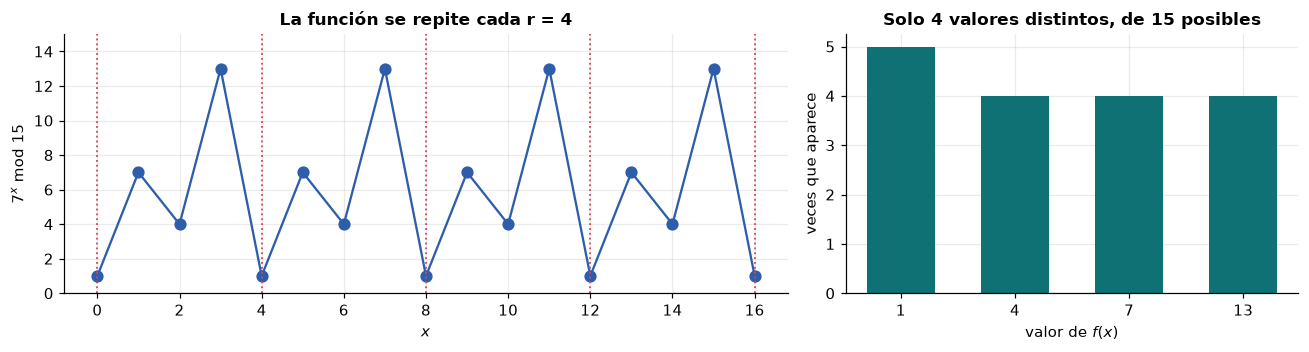

r = 4
a^(r/2) = 4;  gcd(4-1, 15) = 3;  gcd(4+1, 15) = 5
→ factores de 15: (3, 5)


In [5]:
xs = np.arange(0, 17)
ys = [pow(A, int(x), N) for x in xs]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.3),
                               gridspec_kw={"width_ratios": [1.6, 1]})
ax1.plot(xs, ys, "o-", ms=7, color=utils.COLOR_IDEAL)
for k in range(0, 17, 4):
    ax1.axvline(k, color=utils.COLOR_RUIDO, ls=":", lw=1.2)
ax1.set_xlabel("$x$")
ax1.set_ylabel(f"${A}^x$ mod {N}")
ax1.set_xticks(xs[::2])
ax1.set_title(f"La función se repite cada r = 4")
ax1.set_ylim(0, 15)

valores, cuentas = np.unique(ys, return_counts=True)
ax2.bar(range(len(valores)), cuentas, color=utils.COLOR_HARD, width=0.6)
ax2.set_xticks(range(len(valores)))
ax2.set_xticklabels(valores)
ax2.set_xlabel("valor de $f(x)$")
ax2.set_ylabel("veces que aparece")
ax2.set_title("Solo 4 valores distintos, de 15 posibles")
utils.layout(fig)
plt.show()

R = 4
factores, detalle = pasos_clasicos(N, A, R)
print(f"r = {R}")
print(detalle)
print(f"→ factores de {N}: {factores}")

---
# 3. El problema del autoestado, y su solución

QPE necesita un autoestado del operador. Acá el operador es la
**multiplicación modular**

$$U\,|y\rangle = |a\,y \bmod N\rangle .$$

Sus autoestados son

$$|u_s\rangle = \frac{1}{\sqrt r}\sum_{k=0}^{r-1}
   e^{-2\pi i s k/r}\;|a^k \bmod N\rangle,
\qquad
U|u_s\rangle = e^{2\pi i s/r}\,|u_s\rangle,$$

para $s = 0, 1, \ldots, r-1$. Las fases son exactamente $s/r$: si QPE
devuelve
una de ellas, tenemos $r$.

**Pero preparar $|u_s\rangle$ requiere conocer $r$** — que es lo que estamos
buscando. Círculo cerrado.

## La salida

Sumar los $r$ autoestados. Las fases se cancelan salvo en $k = 0$:

$$\frac{1}{\sqrt r}\sum_{s=0}^{r-1}|u_s\rangle
 = \frac{1}{r}\sum_{k=0}^{r-1}\left(\sum_{s=0}^{r-1} e^{-2\pi i sk/r}\right)
   |a^k\rangle
 = \frac{1}{r}\cdot r\,|a^0\rangle = |1\rangle .$$

**El estado $|1\rangle$ —que se prepara con una sola compuerta $X$— es la
superposición uniforme de todos los autoestados.** Y por lo que vimos en el
notebook 08, QPE sobre una superposición devuelve una de las fases al azar,
con probabilidad $|c_s|^2 = 1/r$ para cada una.

Sale un $s/r$ con $s$ uniforme en $\{0, \ldots, r-1\}$, y de ahí se despeja
$r$. **Nunca preparamos un autoestado y nunca hizo falta.**

Vamos a verificarlo numéricamente, porque es el punto más elegante del
algoritmo.

In [6]:
def mult_mod15(a: int, veces: int = 1) -> QuantumCircuit:
    """y → a·y mod 15, como permutación de 4 qubits.

    Para N=15 las multiplicaciones modulares son permutaciones de bits, así que
    salen con SWAPs y NOTs. Para N general esto es aritmética modular completa
    y es carísimo — ver sección 7.
    """
    U = QuantumCircuit(4, name=f"·{a} mod 15")
    for _ in range(veces):
        if a in (2, 13):
            U.swap(2, 3); U.swap(1, 2); U.swap(0, 1)
        if a in (7, 8):
            U.swap(0, 1); U.swap(1, 2); U.swap(2, 3)
        if a in (4, 11):
            U.swap(1, 3); U.swap(0, 2)
        if a in (7, 11, 13):
            for q in range(4):
                U.x(q)
    return U


# ¿implementa realmente y -> a*y mod 15?
U7 = Operator(mult_mod15(A)).data
errores = [y for y in range(1, N) if int(np.argmax(np.abs(U7 @ np.eye(16)[y])))
           != (A * y) % N]
print(f"multiplicación por {A} mod {N}: {'correcta' if not errores else 'MAL en ' + str(errores)}")

# los autoestados, construidos a mano
ciclo = [pow(A, k, N) for k in range(R)]
print(f"\nciclo de a^k: {ciclo}")
print(f"\n{'s':>2} {'autovalor medido':>22} {'e^(2πi s/r) esperado':>24} {'φ = s/r':>9}")
autoestados = []
for s in range(R):
    u = np.zeros(16, dtype=complex)
    for k, val in enumerate(ciclo):
        u[val] += np.exp(-2j * np.pi * s * k / R) / np.sqrt(R)
    autoestados.append(u)
    salida = U7 @ u
    autovalor = salida[np.argmax(np.abs(u))] / u[np.argmax(np.abs(u))]
    esperado = np.exp(2j * np.pi * s / R)
    print(f"{s:>2} {np.round(autovalor, 4)!s:>22} {np.round(esperado, 4)!s:>24} "
          f"{s / R:>9.3f}")

suma = sum(autoestados) / np.sqrt(R)
print(f"\n(1/√r)·Σ|u_s⟩ = {np.round(np.real(suma), 4)}")
print(f"¿es |1⟩? {np.allclose(suma, np.eye(16)[1])}   ← se prepara con una sola X")

multiplicación por 7 mod 15: correcta

ciclo de a^k: [1, 7, 4, 13]

 s       autovalor medido     e^(2πi s/r) esperado   φ = s/r
 0                 (1+0j)                   (1+0j)     0.000
 1                (-0+1j)                       1j     0.250
 2                (-1-0j)                  (-1+0j)     0.500
 3                    -1j                  (-0-1j)     0.750

(1/√r)·Σ|u_s⟩ = [ 0.  1.  0.  0.  0.  0.  0. -0.  0.  0.  0.  0.  0.  0.  0.  0.]
¿es |1⟩? True   ← se prepara con una sola X


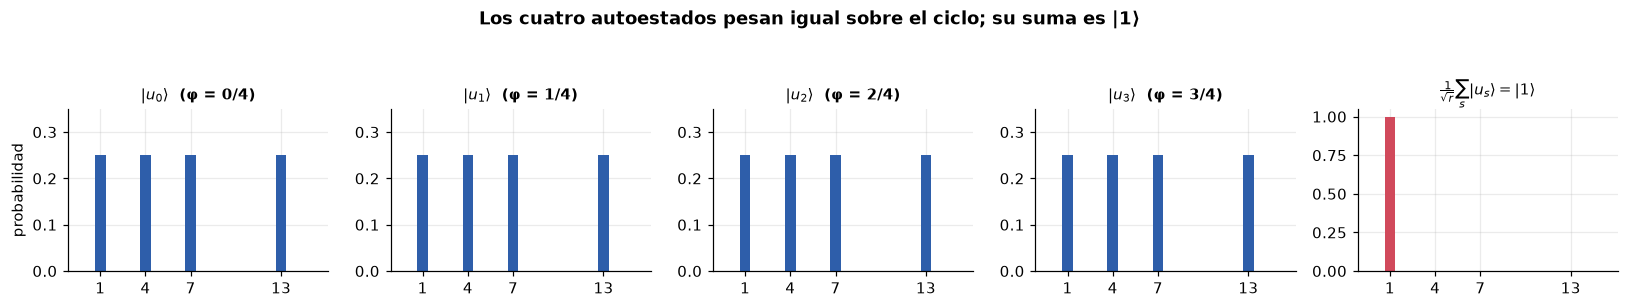

In [7]:
fig, ejes = plt.subplots(1, 5, figsize=(15, 2.6))
for s in range(R):
    ejes[s].bar(range(16), np.abs(autoestados[s]) ** 2, color=utils.COLOR_IDEAL,
                width=0.7)
    ejes[s].set_title(f"$|u_{s}\\rangle$  (φ = {s}/{R})", fontsize=10)
    ejes[s].set_xticks([1, 4, 7, 13])
    ejes[s].set_ylim(0, 0.35)
ejes[4].bar(range(16), np.abs(suma) ** 2, color=utils.COLOR_RUIDO, width=0.7)
ejes[4].set_title(r"$\frac{1}{\sqrt{r}}\sum_s |u_s\rangle = |1\rangle$", fontsize=10)
ejes[4].set_xticks([1, 4, 7, 13])
ejes[4].set_ylim(0, 1.05)
ejes[0].set_ylabel("probabilidad")
fig.suptitle("Los cuatro autoestados pesan igual sobre el ciclo; su suma es |1⟩",
             fontweight="bold", y=1.06)
utils.layout(fig)
plt.show()

Los cuatro autoestados son **indistinguibles en probabilidad**: los cuatro
reparten peso $1/4$ sobre $\{1, 7, 4, 13\}$. Lo que los diferencia son las
**fases**, y por eso al sumarlos interfieren y queda un único $|1\rangle$.

Es el mismo fenómeno que la QFT del notebook 07, leído al revés: una
superposición de fases que giran a ritmos distintos se concentra en un
punto.

---
# 4. El circuito

Es QPE, con $U$ = multiplicación por $a$ módulo $N$, y el target en
$|1\rangle$.

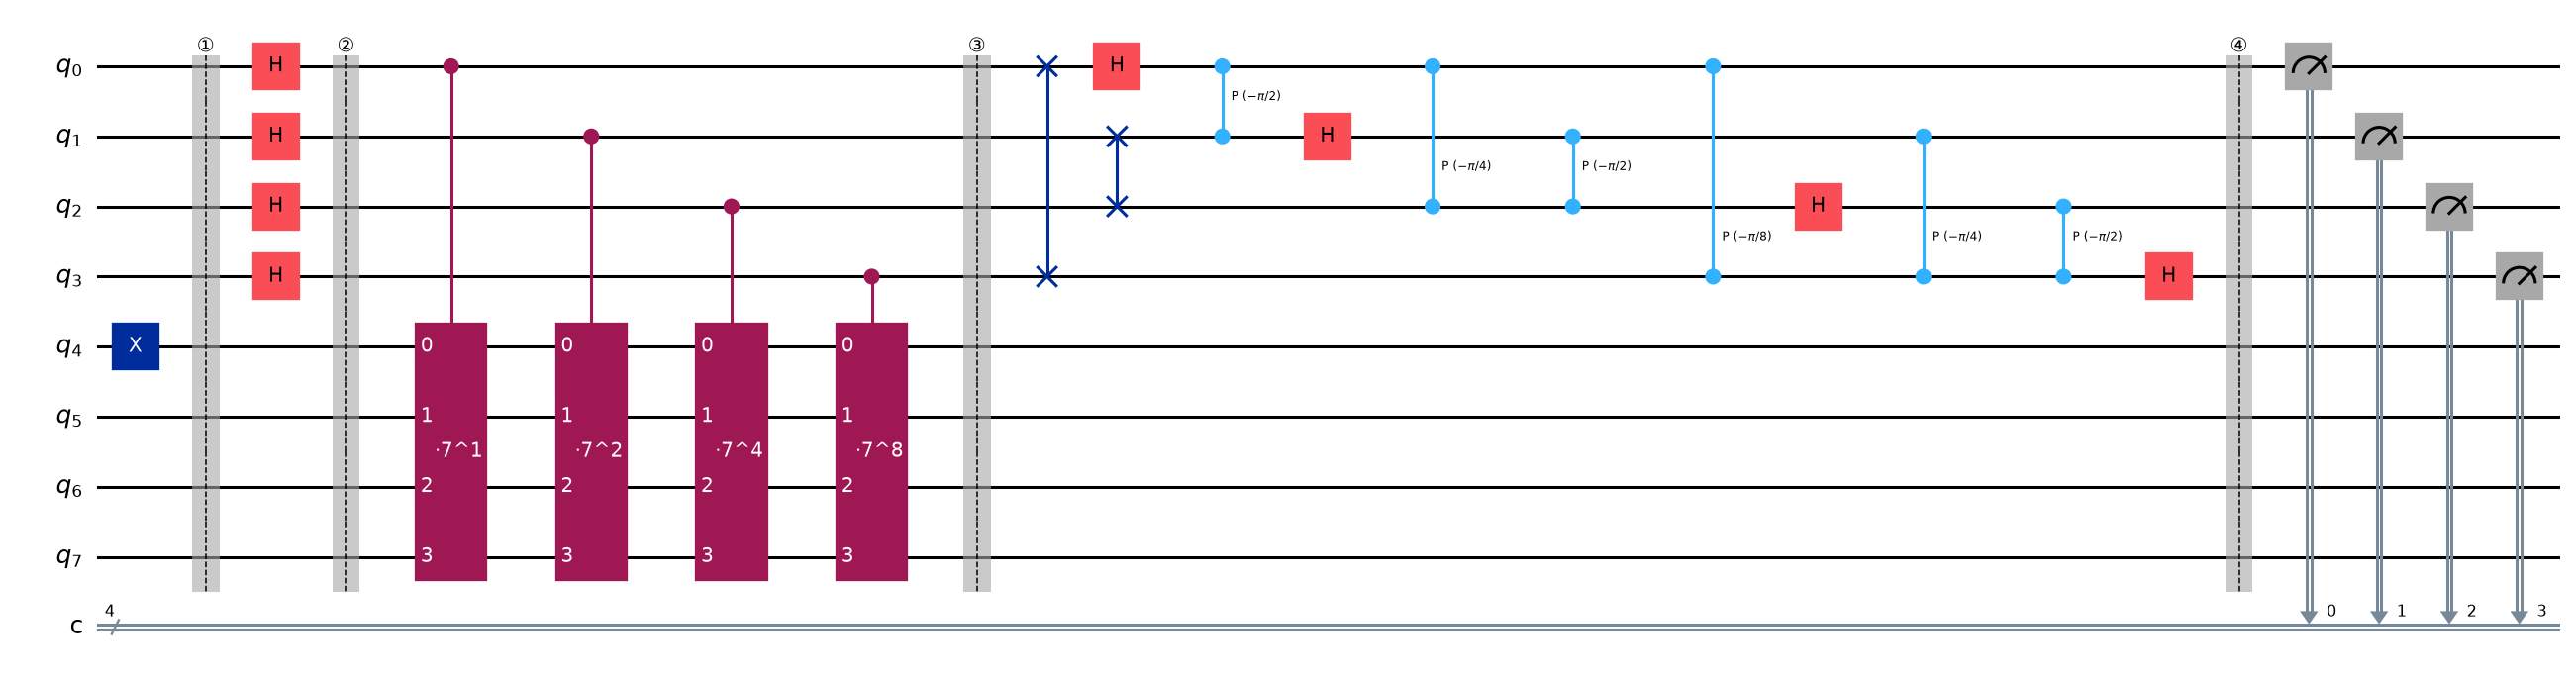


con t=8: 12 qubits, 69 instrucciones


In [8]:
def shor(t: int = 8, a: int = A, medir=True) -> QuantumCircuit:
    """QPE con U = (·a mod 15). t qubits de conteo, 4 de trabajo."""
    qc = QuantumCircuit(t + 4, t) if medir else QuantumCircuit(t + 4)
    qc.x(t)                              # el target en |1>: UNA compuerta
    marca(qc, 1)
    qc.h(range(t))
    marca(qc, 2)
    for j in range(t):                   # U^(2^j) controlada
        g = mult_mod15(pow(a, 2 ** j, N)).to_gate()
        g.name = f"·{a}^{2 ** j}"
        qc.append(g.control(), [j] + list(range(t, t + 4)))
    marca(qc, 3)
    for q in range(t // 2):              # IQFT
        qc.swap(q, t - 1 - q)
    for j in range(t):
        for k in range(j):
            qc.cp(-np.pi / 2 ** (j - k), k, j)
        qc.h(j)
    marca(qc, 4)
    if medir:
        qc.measure(range(t), range(t))
    return qc


T = 8
display(shor(4).draw("mpl", style="iqp", fold=-1))
print(f"\ncon t={T}: {shor(T).num_qubits} qubits, {len(shor(T).data)} instrucciones")

### La cuenta, etapa por etapa

**①** Dado que se aplica $X$ al registro de trabajo:
$$|\psi_1\rangle = |0\rangle_c^{\otimes t} \otimes |1\rangle_w
 = |0\rangle_c \otimes \frac{1}{\sqrt r}\sum_{s} |u_s\rangle .$$
Esa segunda forma es la misma cosa escrita en la base de autoestados, y es
**toda la gracia**: preparamos los cuatro autoestados a la vez sin saber
cuáles son.

**②** Dado que se aplican las $H$ al registro de conteo:
$$|\psi_2\rangle = \frac{1}{\sqrt{2^t}}\sum_{x=0}^{2^t-1}|x\rangle_c
   \otimes |1\rangle_w .$$

**③** Dado que se aplican las $U^{2^j}$ controladas — que equivalen a
$|x\rangle|1\rangle \to |x\rangle|a^x \bmod N\rangle$:
$$|\psi_3\rangle = \frac{1}{\sqrt{2^t}}\sum_x |x\rangle\,|a^x \bmod N\rangle
 = \frac{1}{\sqrt r}\sum_s \left(\frac{1}{\sqrt{2^t}}\sum_x
   e^{2\pi i (s/r) x}|x\rangle\right)\otimes|u_s\rangle .$$
Las dos escrituras son iguales. La segunda muestra que **el registro de
conteo
quedó con una fase que gira a ritmo $s/r$**, entrelazado con el autoestado
correspondiente.

**④** Dado que se aplica la IQFT al registro de conteo, que convierte cada
onda
de frecuencia $s/r$ en el número que la genera:
$$|\psi_4\rangle \approx \frac{1}{\sqrt r}\sum_s
   \left|\,\frac{s}{r}\,2^t\right\rangle_c \otimes |u_s\rangle .$$

Medir el conteo da $\approx s\,2^t/r$ con $s$ uniforme. Con $t = 8$ y $r =
4$:
los picos deberían estar en $0, 64, 128, 192$.

---
# 5. Corriendo el circuito

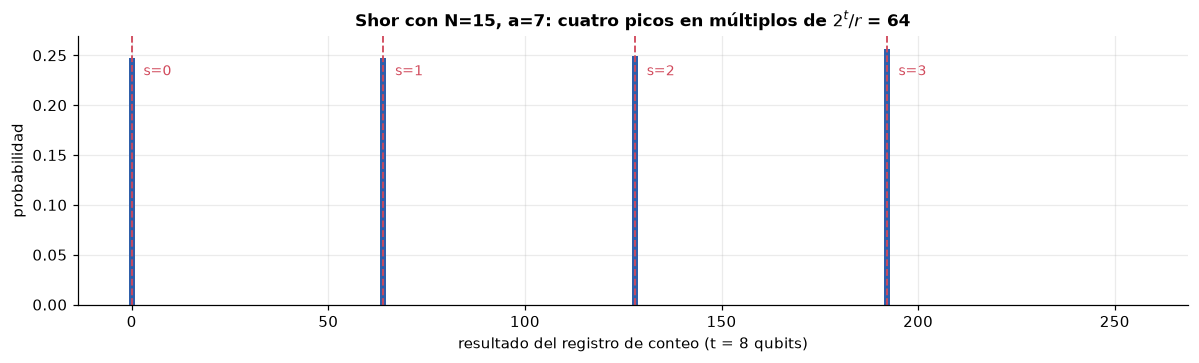

  medido       /2^t   s/r esperado  probabilidad
     192     0.7500         0.7500        0.2563
     128     0.5000         0.5000        0.2493
      64     0.2500         0.2500        0.2476
       0     0.0000         0.0000        0.2468


In [9]:
SHOTS = 4096
counts = utils.correr_ideal(shor(T), shots=SHOTS)

valores = sorted(int(k, 2) for k in counts)
probs = np.zeros(2 ** T)
for k, v in counts.items():
    probs[int(k, 2)] = v / SHOTS

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(range(2 ** T), probs, width=1.6, color=utils.COLOR_IDEAL)
for s in range(R):
    ax.axvline(s * 2 ** T / R, color=utils.COLOR_RUIDO, ls="--", lw=1.2)
    ax.text(s * 2 ** T / R + 3, 0.23, f"s={s}", fontsize=9, color=utils.COLOR_RUIDO)
ax.set_xlabel(f"resultado del registro de conteo (t = {T} qubits)")
ax.set_ylabel("probabilidad")
ax.set_title(f"Shor con N={N}, a={A}: cuatro picos en múltiplos de $2^t/r$ = {2 ** T // R}")
utils.layout(fig)
plt.show()

print(f"{'medido':>8} {'/2^t':>10} {'s/r esperado':>14} {'probabilidad':>13}")
for k, v in sorted(counts.items(), key=lambda kv: -kv[1])[:6]:
    m = int(k, 2)
    print(f"{m:>8} {m / 2 ** T:>10.4f} {round(m / 2 ** T * R) / R:>14.4f} "
          f"{v / SHOTS:>13.4f}")

---
# 6. Fracciones continuas: de la fase al período

El registro devuelve $y \approx s\,2^t/r$, o sea $y/2^t \approx s/r$. Hay
que
despejar $r$ de una aproximación decimal, sabiendo que $r < N$.

La herramienta es la **expansión en fracciones continuas**: dado un número
real, produce la sucesión de fracciones racionales que mejor lo aproximan
con
denominador acotado. Es un algoritmo de Euclides, del siglo III a.C., y en
Python está en `fractions.Fraction.limit_denominator`.

In [10]:
def periodo_desde_medicion(y: int, t: int, N: int):
    """s/r ← y/2^t por fracciones continuas. Devuelve r candidato."""
    frac = Fraction(y, 2 ** t).limit_denominator(N)
    return frac.numerator, frac.denominator


print(f"{'y medido':>9} {'y/2^t':>9} {'fracción':>10} {'r candidato':>12}  ¿verifica a^r≡1?")
for k, v in sorted(counts.items(), key=lambda kv: -kv[1])[:6]:
    y = int(k, 2)
    s, r = periodo_desde_medicion(y, T, N)
    ok = pow(A, r, N) == 1 if r else False
    print(f"{y:>9} {y / 2 ** T:>9.4f} {f'{s}/{r}':>10} {r:>12}  "
          f"{'sí ✓' if ok else 'no'}")

 y medido     y/2^t   fracción  r candidato  ¿verifica a^r≡1?
      192    0.7500        3/4            4  sí ✓
      128    0.5000        1/2            2  no
       64    0.2500        1/4            4  sí ✓
        0    0.0000        0/1            1  no


In [11]:
# La expansión, paso a paso, para uno de los picos
y_demo = 192
print(f"Fracciones continuas de y/2^t = {y_demo}/{2 ** T} = {y_demo / 2 ** T}:\n")
print(f"{'denominador máx.':>18} {'aproximación':>14} {'error':>12}")
for d in range(2, N + 1):
    f = Fraction(y_demo, 2 ** T).limit_denominator(d)
    print(f"{d:>18} {str(f):>14} {abs(float(f) - y_demo / 2 ** T):>12.6f}")
print(f"\ncon denominador < {N} queda "
      f"{Fraction(y_demo, 2 ** T).limit_denominator(N)} → r = "
      f"{Fraction(y_demo, 2 ** T).limit_denominator(N).denominator}")

Fracciones continuas de y/2^t = 192/256 = 0.75:

  denominador máx.   aproximación        error
                 2              1     0.250000
                 3            2/3     0.083333
                 4            3/4     0.000000
                 5            3/4     0.000000
                 6            3/4     0.000000
                 7            3/4     0.000000
                 8            3/4     0.000000
                 9            3/4     0.000000
                10            3/4     0.000000
                11            3/4     0.000000
                12            3/4     0.000000
                13            3/4     0.000000
                14            3/4     0.000000
                15            3/4     0.000000

con denominador < 15 queda 3/4 → r = 4


**Cuidado con el pico $y = 0$.** Da $s = 0$ y no dice nada sobre $r$: es la
componente $|u_0\rangle$, cuyo autovalor es 1. Sale una de cada cuatro veces
y
hay que descartarla.

Y cuidado también con los $s$ que comparten factor con $r$: si sale
$y = 128$, la fracción $1/2$ da $r = 2$, que es un **divisor** de $r$, no
$r$.
Se detecta porque $a^2 = 4 \neq 1 \pmod{15}$, y se descarta.

---
# 7. El algoritmo completo

Juntamos todo: parte cuántica, fracciones continuas, verificación, y los
pasos
clásicos finales. Lo corremos muchas veces para ver la tasa de éxito real.

40 corridas de una sola medición cada una:

    y     r     factores  motivo
  192     4       (3, 5)  a^(r/2) = 4;  gcd(4-1, 15) = 3;  gcd(4+1, 15) = 5
  128     2         None  r = 2 no verifica a^r ≡ 1
  128     2         None  r = 2 no verifica a^r ≡ 1
  128     2         None  r = 2 no verifica a^r ≡ 1
   64     4       (3, 5)  a^(r/2) = 4;  gcd(4-1, 15) = 3;  gcd(4+1, 15) = 5
  192     4       (3, 5)  a^(r/2) = 4;  gcd(4-1, 15) = 3;  gcd(4+1, 15) = 5
    0  None         None  y = 0: no informa sobre r
  192     4       (3, 5)  a^(r/2) = 4;  gcd(4-1, 15) = 3;  gcd(4+1, 15) = 5
  192     4       (3, 5)  a^(r/2) = 4;  gcd(4-1, 15) = 3;  gcd(4+1, 15) = 5
    0  None         None  y = 0: no informa sobre r
  192     4       (3, 5)  a^(r/2) = 4;  gcd(4-1, 15) = 3;  gcd(4+1, 15) = 5
  192     4       (3, 5)  a^(r/2) = 4;  gcd(4-1, 15) = 3;  gcd(4+1, 15) = 5

éxito en 23/40 = 57% de las corridas
factores encontrados: {(3, 5)}


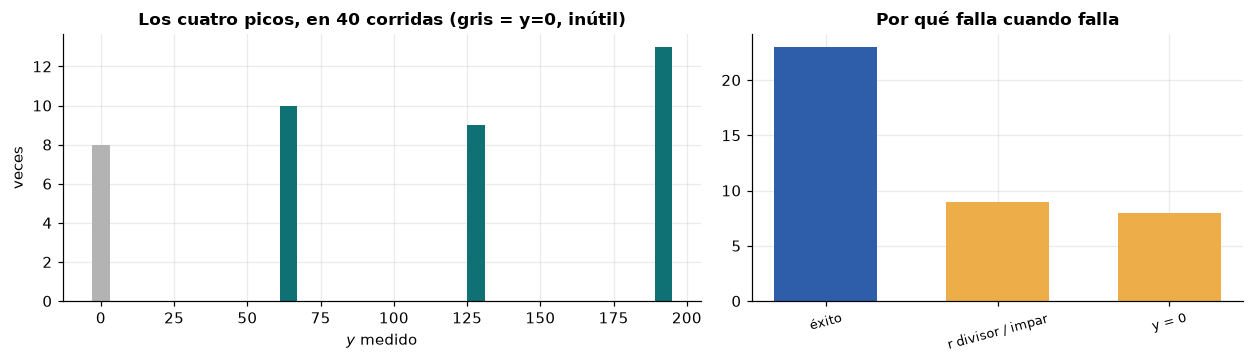

In [12]:
def shor_completo(N, a, t=8, shots=1, rng=None, verbose=False):
    """Una pasada completa. Devuelve (factores, r, y) o (None, ...) si falla."""
    c = utils.correr_ideal(shor(t, a), shots=shots)
    poblacion = [k for k, v in c.items() for _ in range(v)]
    y = int(poblacion[(rng or np.random).integers(len(poblacion))
                      if rng is not None else 0], 2)
    if y == 0:
        return None, None, y, "y = 0: no informa sobre r"
    s, r = periodo_desde_medicion(y, t, N)
    if r == 0 or pow(a, r, N) != 1:
        return None, r, y, f"r = {r} no verifica a^r ≡ 1"
    factores, motivo = pasos_clasicos(N, a, r)
    return factores, r, y, motivo


rng = np.random.default_rng(2026)
resultados = []
for intento in range(40):
    f, r, y, motivo = shor_completo(N, A, T, shots=1, rng=rng)
    resultados.append((y, r, f, motivo))

exitos = [r for r in resultados if r[2]]
print(f"40 corridas de una sola medición cada una:\n")
print(f"{'y':>5} {'r':>5} {'factores':>12}  motivo")
for y, r, f, motivo in resultados[:12]:
    print(f"{y:>5} {str(r):>5} {str(f):>12}  {motivo[:52]}")
print(f"\néxito en {len(exitos)}/40 = {len(exitos) / 40:.0%} de las corridas")
print(f"factores encontrados: {set(f[2] for f in resultados if f[2])}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.4),
                               gridspec_kw={"width_ratios": [1.3, 1]})
ys_hist = {}
for y, r, f, _ in resultados:
    ys_hist[y] = ys_hist.get(y, 0) + 1
ax1.bar(list(ys_hist), list(ys_hist.values()),
        color=[utils.COLOR_HARD if y != 0 else "0.7" for y in ys_hist], width=6)
ax1.set_xlabel("$y$ medido")
ax1.set_ylabel("veces")
ax1.set_title("Los cuatro picos, en 40 corridas (gris = y=0, inútil)")

motivos = {}
for _, _, f, m in resultados:
    clave = "éxito" if f else ("y = 0" if "y = 0" in m else "r divisor / impar")
    motivos[clave] = motivos.get(clave, 0) + 1
ax2.bar(range(len(motivos)), list(motivos.values()),
        color=[utils.COLOR_IDEAL if k == "éxito" else utils.PALETA[3]
               for k in motivos], width=0.6)
ax2.set_xticks(range(len(motivos)))
ax2.set_xticklabels(list(motivos), fontsize=8.5, rotation=15)
ax2.set_title("Por qué falla cuando falla")
utils.layout(fig)
plt.show()

**La tasa de éxito por corrida es de alrededor del 50 %**, y eso está bien:
el
algoritmo es probabilístico por diseño. Se corre dos o tres veces y alcanza.
Lo
importante es que **verificar** es barato: multiplicar los factores y ver si
dan $N$ cuesta nada.

Esa asimetría —encontrar es difícil, verificar es trivial— es la misma en la
que se apoya RSA.

---
# 8. Por qué en NISQ sale ruido plano

Acá están los números, que es lo único que hace falta para cerrar la
discusión.

In [13]:
pm = generate_preset_pass_manager(optimization_level=3, backend=fez)
print(f"{'t':>2} {'qubits':>7} {'profundidad':>12} {'2q gates':>10} "
      f"{'tiempo est.':>12}")
for t in (3, 4, 6, 8):
    tq = pm.run(shor(t))
    n2 = sum(v for k, v in tq.count_ops().items() if k in ("cz", "ecr", "cx"))
    # tiempo aproximado: profundidad × duración típica de compuerta en Heron
    t_est = tq.depth() * 80e-9
    print(f"{t:>2} {shor(t).num_qubits:>7} {tq.depth():>12} {n2:>10} "
          f"{t_est * 1e6:>10.1f} µs")

props = fez.properties()
err_2q = np.median([props.gate_error("cz", list(q)) for q in
                    [g for g in fez.target["cz"].keys()][:60]])
t2 = np.median([props.t2(q) for q in range(fez.num_qubits)])
tq8 = pm.run(shor(8))
n2_8 = sum(v for k, v in tq8.count_ops().items() if k in ("cz", "ecr", "cx"))
print(f"\nerror típico por compuerta de 2 qubits en ibm_fez: {err_2q:.4f}")
print(f"con {n2_8} compuertas de 2 qubits, la probabilidad de que NINGUNA falle es")
print(f"   (1 - {err_2q:.4f})^{n2_8} = {(1 - err_2q) ** n2_8:.2e}")
print(f"\nT2 mediano: {t2 * 1e6:.0f} µs   ·   duración del circuito: "
      f"{tq8.depth() * 80e-9 * 1e6:.0f} µs   → "
      f"{tq8.depth() * 80e-9 / t2:.1f} tiempos de coherencia")

 t  qubits  profundidad   2q gates  tiempo est.
 3       7          507        142       40.6 µs
 4       8          533        157       42.6 µs
 6      10          595        192       47.6 µs
 8      12          669        243       53.5 µs

error típico por compuerta de 2 qubits en ibm_fez: 0.0038
con 233 compuertas de 2 qubits, la probabilidad de que NINGUNA falle es
   (1 - 0.0038)^233 = 4.12e-01

T2 mediano: 88 µs   ·   duración del circuito: 52 µs   → 0.6 tiempos de coherencia


**Con esos dos números alcanza.** Con ~300 compuertas de dos qubits al
0.3 % de error cada una, la probabilidad de que el circuito entero salga
limpio es del orden de $10^{-1}$ o peor; y el circuito dura varias veces el
$T_2$ del chip, así que las fases —que es donde vive toda la información de
Shor— ya se perdieron mucho antes del final.

El resultado es **ruido plano**: una
distribución uniforme sobre los $2^t$ resultados, exactamente lo mismo que
daría un generador de números al azar.

Vamos a verlo, con $t = 5$ para que la simulación con ruido termine en un
tiempo razonable.

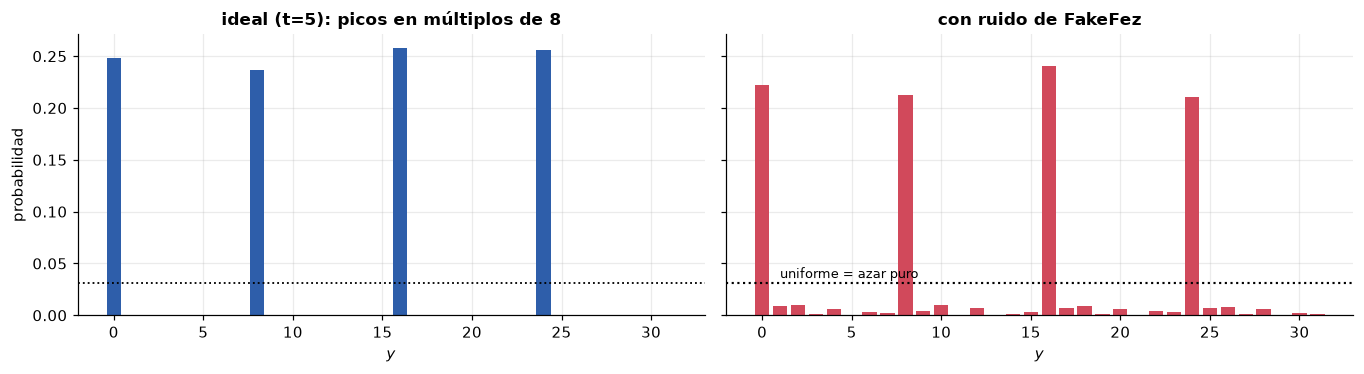

distancia de variación total a la distribución uniforme:
  ideal   : 0.8750   (lejos del azar: hay estructura)
  ruidoso : 0.7607   (cerca del azar: la estructura se perdió)

probabilidad concentrada en los 4 picos correctos:
  ideal   : 1.000
  ruidoso : 0.886   (si fuera azar puro daría 0.125)


In [14]:
T_RUIDO = 5
counts_ideal_5 = utils.correr_ideal(shor(T_RUIDO), shots=2048)
counts_ruido_5 = utils.correr_ruidoso(shor(T_RUIDO), backend_falso=fez, shots=2048,
                                      opt=1)

p_i = np.array([counts_ideal_5.get(format(k, f"0{T_RUIDO}b"), 0) / 2048
                for k in range(2 ** T_RUIDO)])
p_r = np.array([counts_ruido_5.get(format(k, f"0{T_RUIDO}b"), 0) / 2048
                for k in range(2 ** T_RUIDO)])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 3.5), sharey=True)
ax1.bar(range(2 ** T_RUIDO), p_i, color=utils.COLOR_IDEAL, width=0.8)
ax1.axhline(1 / 2 ** T_RUIDO, color="k", ls=":", lw=1.2)
ax1.set_title(f"ideal (t={T_RUIDO}): picos en múltiplos de {2 ** T_RUIDO // R}")
ax1.set_xlabel("$y$"); ax1.set_ylabel("probabilidad")
ax2.bar(range(2 ** T_RUIDO), p_r, color=utils.COLOR_RUIDO, width=0.8)
ax2.axhline(1 / 2 ** T_RUIDO, color="k", ls=":", lw=1.4)
ax2.text(1, 1 / 2 ** T_RUIDO * 1.15, "uniforme = azar puro", fontsize=8.5)
ax2.set_title("con ruido de FakeFez")
ax2.set_xlabel("$y$")
utils.layout(fig)
plt.show()

# cuánto se parece cada distribución a la uniforme
uniforme = np.ones(2 ** T_RUIDO) / 2 ** T_RUIDO
dist_i = 0.5 * np.abs(p_i - uniforme).sum()
dist_r = 0.5 * np.abs(p_r - uniforme).sum()
print(f"distancia de variación total a la distribución uniforme:")
print(f"  ideal   : {dist_i:.4f}   (lejos del azar: hay estructura)")
print(f"  ruidoso : {dist_r:.4f}   (cerca del azar: la estructura se perdió)")
pico_i = sum(p_i[[s * 2 ** T_RUIDO // R for s in range(R)]])
pico_r = sum(p_r[[s * 2 ** T_RUIDO // R for s in range(R)]])
print(f"\nprobabilidad concentrada en los 4 picos correctos:")
print(f"  ideal   : {pico_i:.3f}")
print(f"  ruidoso : {pico_r:.3f}   (si fuera azar puro daría {4 / 2 ** T_RUIDO:.3f})")

Con $t = 5$ el circuito todavía es chico y el ruido **no** lo mata del todo:
se ve estructura degradada. Con $t = 8$ —que es lo que hace falta para que
las
fracciones continuas funcionen bien— la estructura desaparece.

## 8.1 Lo que se publica como "Shor en hardware"

Desde 2001 salen papers factorizando 15, 21 y 35 en hardware. Casi todos
usan
alguna de estas simplificaciones:

- **Circuitos precompilados sabiendo la respuesta.** Si ya se sabe que $r =
4$,
  se puede simplificar las multiplicaciones controladas hasta dejar un circuito
  trivial. Es legítimo como demostración de control, pero no factoriza nada:
  la respuesta estaba puesta a mano en el circuito.
- **Elegir $a$ de orden 2**, que hace la aritmética casi trivial.
- **Reciclar un solo qubit de conteo** (QPE iterativa, `08`), que reduce
  qubits pero no compuertas.

Una crítica conocida ("Pretending to factor large numbers on a quantum
computer", Smolin, Smith y Vargo, 2013) mostró que con esas simplificaciones
se puede "factorizar" números arbitrariamente grandes con dos qubits, sin
hacer nada. La prueba de fuego es: **¿el circuito se construyó sin conocer
la
respuesta?**

## 8.2 Cuánto falta de verdad

Para RSA-2048 harían falta del orden de **20 millones de qubits físicos**
con
corrección de errores, corriendo unas ocho horas (Gidney y Ekerå, 2019). El
chip que usamos tiene 156 qubits físicos sin corrección. La brecha no es de
ingeniería incremental: es de cinco órdenes de magnitud.

## 8.3 El sustituto honesto

Si hace falta mostrar en hardware el mecanismo que hace funcionar a Shor, correr
**QPE de 3 qubits sobre una fase conocida** (`08_qpe.ipynb`). Es el mismo
retroceso de fase, la misma IQFT, la misma lectura en binario — y sale un
pico
limpio en el chip real.

Y mostrar el ruido plano donde el titular prometía factorización **también
es
una clase**. Por eso este notebook no tiene celda de envío, y la ausencia es
deliberada: gastar QPU acá daría un histograma uniforme por varios segundos
de una cuota de 10 minutos.

---
## Qué quedó establecido

1. **Shor no factoriza: encuentra períodos.** El resto es aritmética clásica
   con gcd, y falla con probabilidad acotada.
2. **El problema del autoestado tiene solución.** $|1\rangle$ es la
superposición
   uniforme de los $r$ autoestados de la multiplicación modular, y se
     prepara
   con una $X$. QPE muestrea uno al azar.
3. **Las fracciones continuas** convierten $y/2^t$ en $s/r$ y despejan $r$.
   Los casos $y=0$ y $s$ con factor común se detectan y se descartan.
4. En simulador, con $N=15$ y $a=7$, el algoritmo completo factoriza en
   ~50 % de las corridas, y verificar es gratis.
5. **En NISQ sale ruido plano**, y los números lo predicen: ~300 compuertas
de
   dos qubits y una duración de varios $T_2$.
6. Lo que se publica como "Shor en hardware" suele ser precompilado. La
   pregunta correcta es si el circuito se armó sin conocer la respuesta.

**Fin de la serie.** El recorrido completo: `01` → `01b` → `02` → `03` →
`04` → `05` → `06` → `07` → `08` → `09`.